# 12 — Build and evaluate our first ML research dataset

**Question:** Can we build a model using only information available at decision time?

**By the end:** separate features from labels, inspect missingness, purge overlapping
intervals, fit preprocessing only on training data, and compare a simple model
with a baseline. **Time:** 40–50 minutes.

**Inputs:** the recorded sample; additional prepared windows are optional. With
one window, we run a clearly labeled chronological pipeline demonstration. It
does **not** estimate generalization to new markets, validate terminal calibration,
or produce a deployable trading algorithm.

In [1]:
import sys
from pathlib import Path

for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.advanced import (
    FEATURES,
    chronological_split,
    classifier_demo,
    combine_datasets,
    feature_dataset,
)
from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    finish_plot,
    plot_style,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Define the target before choosing a model

Target 1 means the observed Up midpoint is strictly higher five seconds later;
target 0 includes unchanged or lower prices. It is not “terminal Up wins” and not
“a trade makes profit.” Missing forward prices have no target, not target zero.

The builder reads books, BTC trades and operations. It never reads resolution
observations, retrospective quality scores or future metadata as model features.

In [2]:
study = BookStudy(sample)
data = feature_dataset(sample, study)
display(
    data[
        [
            "time",
            "mid",
            "imbalance",
            "btc_volatility_bps",
            "forward_move_cents",
            "target_rise",
            "research_row_eligible",
        ]
    ].head(25)
)
assert data.loc[data.forward_move_cents.isna(), "target_rise"].isna().all()
display(pd.Series(data.attrs, name="Dataset definition"))

,time,mid,imbalance,btc_volatility_bps,forward_move_cents,target_rise,research_row_eligible
0,2026-10-01 15:45:00+00:00,0.645,-0.946179,NaN,NaN,<NA>,False
1,2026-10-01 15:45:01+00:00,0.615,-0.782609,NaN,NaN,<NA>,False
2,2026-10-01 15:45:02+00:00,0.615,0.974640,NaN,NaN,<NA>,False
3,2026-10-01 15:45:03+00:00,0.665,-0.371341,NaN,NaN,<NA>,False
4,2026-10-01 15:45:04+00:00,0.665,-0.819971,NaN,NaN,<NA>,False
5,2026-10-01 15:45:05+00:00,0.665,-0.784268,NaN,NaN,<NA>,False
6,2026-10-01 15:45:06+00:00,0.665,-0.912399,NaN,NaN,<NA>,False
7,2026-10-01 15:45:07+00:00,0.655,0.962269,NaN,NaN,<NA>,False
8,2026-10-01 15:45:08+00:00,0.715,0.741396,NaN,1.0,1,False
9,2026-10-01 15:45:09+00:00,0.735,-0.903100,NaN,1.0,1,False


target                    next_midpoint_rises_not_terminal_Up
lookback_s                                                 20
horizon_s                                                   5
settlement_labels_used                                  False
Name: Dataset definition, dtype: object

## 2. Seven causal features, not every numeric column

The declared feature list contains the current quote state, expiry clock and
trailing BTC behavior. Twenty-return volatility needs twenty past returns.
`label_end`, `target_rise` and `forward_move_cents` are deliberately excluded.
Partial observed OFI remains an optional candidate rather than silently imputing
missing OFI as zero.

,feature,unit,meaning
0,mid,USD/share,current eligible Up midpoint
1,spread_cents,cents/share,current ask minus bid
2,imbalance,dimensionless,current best bid/ask quantity balance
3,seconds_left,seconds,scheduled deadline minus decision time
4,quote_age_s,seconds,age of selected book update
5,btc_return_1s_bps,basis points,current versus prior causal sampled BTC price
6,btc_volatility_bps,basis points,trailing 20-return standard deviation


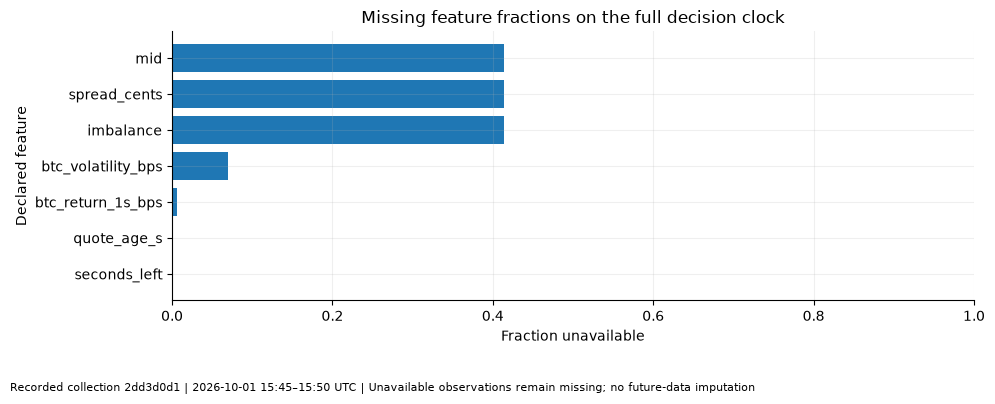

grid_rows                    300
feature_ready                155
labeled_and_feature_ready    109
dtype: int64

In [3]:
feature_dictionary = pd.DataFrame(
    [
        ("mid", "USD/share", "current eligible Up midpoint"),
        ("spread_cents", "cents/share", "current ask minus bid"),
        ("imbalance", "dimensionless", "current best bid/ask quantity balance"),
        ("seconds_left", "seconds", "scheduled deadline minus decision time"),
        ("quote_age_s", "seconds", "age of selected book update"),
        ("btc_return_1s_bps", "basis points", "current versus prior causal sampled BTC price"),
        ("btc_volatility_bps", "basis points", "trailing 20-return standard deviation"),
    ],
    columns=["feature", "unit", "meaning"],
)
display(feature_dictionary)
missing = data[list(FEATURES)].isna().mean().sort_values()
fig, ax = plt.subplots()
ax.barh(missing.index, missing.values)
ax.set(
    title="Missing feature fractions on the full decision clock",
    xlabel="Fraction unavailable",
    ylabel="Declared feature",
    xlim=(0, 1),
)
finish_plot(fig, sample, "Unavailable observations remain missing; no future-data imputation")
display(
    pd.Series(
        {
            "grid_rows": len(data),
            "feature_ready": int(data.features_ready.sum()),
            "labeled_and_feature_ready": int(data.research_row_eligible.sum()),
        }
    )
)

## 3. Independent windows determine the evaluation mode

Adding prepared samples lets the same notebook hold out later entire markets.
Duplicate market IDs are rejected. The current default has one window, so we
use an explicitly named **within_window_demo**. Holding out later rows from this
same window does not create an independent new-market test.

In [4]:
ADDITIONAL_SAMPLE_PATHS = []  # Add other prepared market samples when available.
frames = [data]
for path in ADDITIONAL_SAMPLE_PATHS:
    other = Sample.open(path)
    frames.append(feature_dataset(other))
dataset = combine_datasets(frames)
mode = "markets" if dataset.market_id.nunique() >= 2 else "within_window_demo"
split = chronological_split(dataset, mode=mode)
display(pd.Series({k: v for k, v in split.items() if k not in ("train", "test")}))
train, test = split["train"], split["test"]
display(
    pd.DataFrame(
        {
            "partition": ["train", "held-out"],
            "rows": [len(train), len(test)],
            "rise_fraction": [train.target_rise.mean(), test.target_rise.mean()],
        }
    )
)

mode                                     within_window_demo
purged_rows                                              15
purge_before                      2026-10-01 15:46:37+00:00
training_markets                                          1
heldout_markets                                           1
independent_new_market_holdout                        False
dtype: object

,partition,rows,rise_fraction
0,train,55,0.581818
1,held-out,39,0.692308


## 4. Purge both future labels and backward feature overlap

A training label must finish strictly before the earliest held-out feature
lookback begins. This deliberately conservative policy removes boundary rows.
Extra embargo is available. We do not shuffle rows or fit a scaler on the full
dataset. The [time-series evaluation guidance](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split)
motivates chronological evaluation; market groups and overlapping label/lookback
intervals require the additional controls shown here.

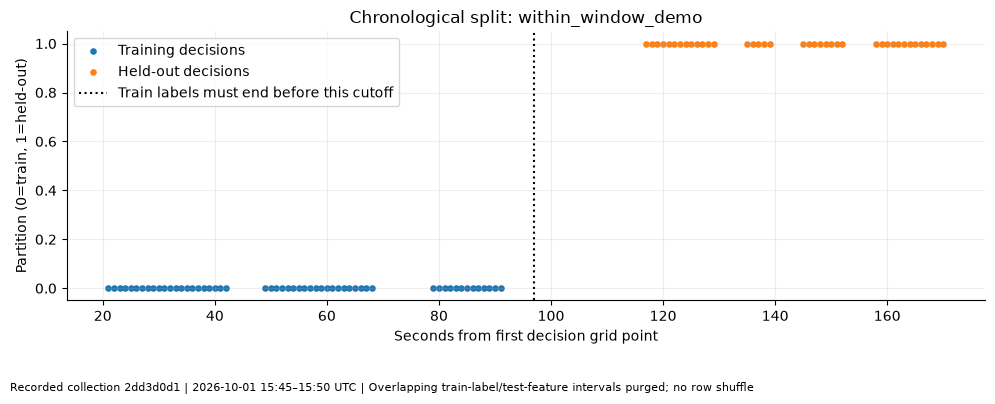

In [5]:
assert train.label_end.max() < test.feature_start.min()
if mode == "markets":
    assert set(train.market_id).isdisjoint(set(test.market_id))
fig, ax = plt.subplots()
origin = dataset.time.min()
ax.scatter(
    (train.time - origin).dt.total_seconds(), np.zeros(len(train)), label="Training decisions", s=14
)
ax.scatter(
    (test.time - origin).dt.total_seconds(), np.ones(len(test)), label="Held-out decisions", s=14
)
ax.axvline(
    (split["purge_before"] - origin).total_seconds(),
    color="black",
    linestyle=":",
    label="Train labels must end before this cutoff",
)
ax.set(
    title=f"Chronological split: {mode}",
    xlabel="Seconds from first decision grid point",
    ylabel="Partition (0=train, 1=held-out)",
)
ax.legend()
finish_plot(fig, sample, "Overlapping train-label/test-feature intervals purged; no row shuffle")

## 5. Fit a baseline and one small fixed model

The baseline predicts the training rise fraction for every held-out row. The
model is regularized logistic regression with StandardScaler inside a Pipeline.
Both preprocessing and model fit use training rows only. Hyperparameters are fixed;
we do not search the test set. If training has only one class, the model is skipped
and the baseline remains available.

See [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
Book Up price is not a probability of the next quote rising, so it is not used as
a mislabeled probability baseline for this target.

In [6]:
result = classifier_demo(split)
display(result["metrics"])
print("Training status:", result["status"])
print("Probability target:", result["probability_target"])
if result["pipeline"] is not None:
    fitted_scaler = result["pipeline"].named_steps["standardscaler"]
    assert np.allclose(
        fitted_scaler.mean_, train[list(FEATURES)].to_numpy(dtype=float).mean(axis=0)
    )
    display(
        pd.Series(
            result["pipeline"].named_steps["logisticregression"].coef_[0],
            index=FEATURES,
            name="Standardized model coefficients (descriptive only)",
        )
    )

,model,test_rows,accuracy,brier_score,log_loss
0,constant_training_prior,39,0.692308,0.225226,0.64321
1,logistic_probability,39,0.717949,0.201514,0.59093


Training status: fixed_model_fitted_no_tuning
Probability target: next_midpoint_rise_not_settlement_or_profit


mid                  -0.165963
spread_cents          0.212064
imbalance             0.205118
seconds_left         -0.138097
quote_age_s           0.178391
btc_return_1s_bps     0.132243
btc_volatility_bps   -0.052067
Name: Standardized model coefficients (descriptive only), dtype: float64

## 6. Read the probabilities and scores for the correct event

Brier score measures squared probability error, while accuracy thresholds at 50%.
Neither metric measures cash profit. A higher probability that the quote rises
does not supply a profitable entry price, move magnitude, fill, or exit.
Any scores from our one-window split are an educational pipeline check only.

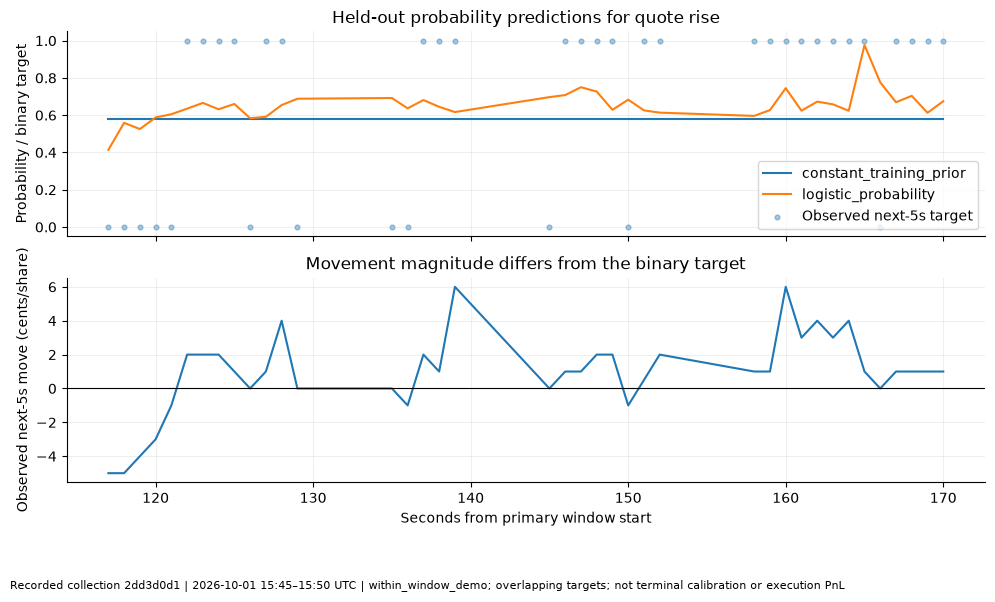

In [7]:
predictions = result["predictions"]
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = (predictions.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
for column in ["constant_training_prior", "logistic_probability"]:
    if column in predictions:
        axes[0].plot(x, predictions[column], label=column)
axes[0].scatter(x, predictions.target_rise, s=12, alpha=0.4, label="Observed next-5s target")
axes[0].set(
    title="Held-out probability predictions for quote rise", ylabel="Probability / binary target"
)
axes[0].legend()
axes[1].plot(x, predictions.forward_move_cents)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(
    title="Movement magnitude differs from the binary target",
    xlabel="Seconds from primary window start",
    ylabel="Observed next-5s move (cents/share)",
)
finish_plot(fig, sample, f"{mode}; overlapping targets; not terminal calibration or execution PnL")

## 7. Calibration bins need counts and independent data

The following descriptive bins compare average predictions with the observed
rise fraction. Sparse bins and dependent targets make this a poor calibration
estimate. It demonstrates the workflow; it does not qualify a probability model.

,count,mean_prediction,observed_rise_fraction
bin,,,
"(0.4, 0.6]",7,0.551089,0.285714
"(0.6, 0.8]",31,0.665630,0.774194
"(0.8, 1.0]",1,0.976270,1.0


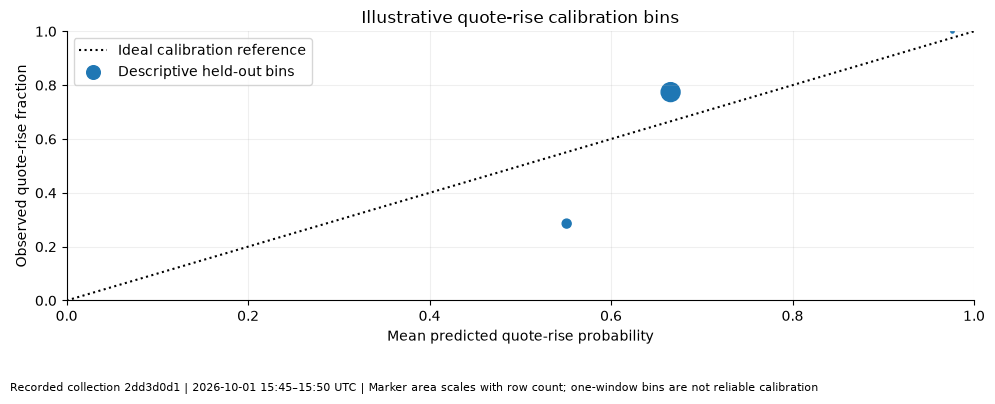

In [8]:
probability_column = (
    "logistic_probability" if "logistic_probability" in predictions else "constant_training_prior"
)
calibration = predictions.copy()
calibration["bin"] = pd.cut(
    calibration[probability_column], np.linspace(0, 1, 6), include_lowest=True
)
calibration_table = calibration.groupby("bin", observed=True).agg(
    count=("target_rise", "size"),
    mean_prediction=(probability_column, "mean"),
    observed_rise_fraction=("target_rise", "mean"),
)
display(calibration_table)
fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], linestyle=":", color="black", label="Ideal calibration reference")
ax.scatter(
    calibration_table.mean_prediction,
    calibration_table.observed_rise_fraction,
    s=calibration_table["count"] * 6,
    label="Descriptive held-out bins",
)
ax.set(
    title="Illustrative quote-rise calibration bins",
    xlabel="Mean predicted quote-rise probability",
    ylabel="Observed quote-rise fraction",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
finish_plot(
    fig, sample, "Marker area scales with row count; one-window bins are not reliable calibration"
)

## 8. What would make this a serious research experiment?

Expand the date range and representative regimes; qualify archive/feed semantics;
hold out later markets or calendar blocks; preserve uncertainty from dependencies;
compare fixed baselines; log every attempted feature/model variant; then evaluate
execution costs and inventory risk separately. Terminal prediction needs qualified
terminal labels. Maker strategies additionally need defensible fill assumptions.

In [9]:
handoff = {
    "dataset_target": result["probability_target"],
    "evaluation_mode": mode,
    "new_market_holdout": split["independent_new_market_holdout"],
    "training_markets": split["training_markets"],
    "heldout_markets": split["heldout_markets"],
    "training_rows": len(train),
    "heldout_rows": len(test),
    "purged_rows": split["purged_rows"],
    "terminal_labels_used": False,
    "actual_fills_or_profit_validated": False,
    "deployment_ready": False,
    "next_research_gate": "representative later windows and economic validation",
}
display(pd.Series(handoff, name="Research handoff"))

dataset_target                            next_midpoint_rise_not_settlement_or_profit
evaluation_mode                                                    within_window_demo
new_market_holdout                                                              False
training_markets                                                                    1
heldout_markets                                                                     1
training_rows                                                                      55
heldout_rows                                                                       39
purged_rows                                                                        15
terminal_labels_used                                                            False
actual_fills_or_profit_validated                                                False
deployment_ready                                                                False
next_research_gate                  representative lat

## Exercise — improve the experiment, not just the score

Add another prepared window, rerun the whole notebook, and inspect the split.
Then propose one additional causal feature and a reason it might help. Keep the
held-out experiment untouched while developing it on earlier data.

**Suggested answer:** an independent later market improves the evaluation design,
but two windows are still far too few for stable conclusions. A well-defined flow
feature could be useful, but missingness, snapshot resets and costs must be handled.
A test-score increase after repeatedly changing the model can be selection bias.

You have completed the twelve-lesson course: data identity and quality, market
lifecycle, BTC statistics, books and flow, expiry, cross-feed alignment, models,
economics, research discipline and a first ML pipeline. This is a foundation for
strategy research, not a promise of profitability.